# Finding and Analzying Growth Stocks to Support Investment Decisions

## Introduction
This project identifies high-potential growth stocks, collects data for them, and uses NLP techniques with statistical visualization to rank companies by positivity to support investment decisions. My custom webspider uses BFS to collect contexts for 6 companies in 4 sectors.

### SMART Objectives:
By 10th of March:
1. **Build a webscraper** using BeautifulSoup to extract growth stocks from Investopedia’s “Best Growth Stocks” list
2. **Deploy a BFS webspider** starting from 10+ financial sites (e.g., Seeking Alpha) for company and sector contexts
3. **Design an SQLite database** (stockAnalysis.db) with tables for stock info, company contexts, and sector contexts, storing 200+ records
4. **Clean data**, **calculate sentiment scores**, and **merge company/sector data**
5. **Visualize data**: sentiment boxplots, word clouds, and weighted sector scores
6. **Build Unit Tests** around the database handler, websraper and webspider classes to make sure they work as expected, and don't break with later changes

## Growth Stocks

### What Is a Growth Stock?
A growth stock is any share in a company that is anticipated to grow at a rate significantly above the average growth for the market$^1$

### What are the benefits of investing in growth stocks?
These companies typically reinvest their earnings into the business to fuel further expansion, which often leads to impressive revenue and profit growth over time.

## Ethical Considerations
- *Compliance with Terms of Service and Data Privacy*: All the data used in this analysis is publicly available. I made sure to scrape websites responsibly by using error handling and rate limiting to reduce any impact on their servers. No personal or sensitive data was collected during this process
- *Transparency and Reproducibility*: Every step of the data processing, analysis, and the code itself is fully documented in this report. I’ve structured the project so that anyone can follow the entire data pipeline—from data collection to the final analysis. This level of transparency not only makes my work easier to evaluate and review but also ensures that the conclusions are well-supported and can be replicated by others
- *Impact on Stakeholders*: Although this analysis is designed to provide insights into stock sentiment, it’s important to remember that any financial decisions based on sentiment analysis can have real-world consequences. The results presented here are for academic and exploratory purposes only. Anyone considering using this analysis for investment decisions should look for further validation and consult with financial experts

---

## SQLight Database
Create a database to store the data collected by the webscraper and webspider for later analysis

**Considerations**:
- Rarely, but it can happen that one company has more tickers
- When looking for tickers, it may not be possible to scrape company name and sector from the texts at first, so those are optional, can be filled with later searches
- Context refers to the text scraped from the page where the company and/or sector was mentioned
- Link is the URL of the website where the ccompany and/or sector was mentioned


<div align="left">
    
| Tables         | Columns                                      |
|:---------------|:---------------------------------------------|
| **stock_info** | Ticker - text, primary key  |
|               | Company name - optional text  |
|               | Sector - optional text  |
|               | Investopedia_link - optional text  |
| **company_context** | Company - text  |
|               | Context - optional text  |
|               | Link - optional text  |
| **sector_context** | Sector - text  |
|               | Context - optional text  |
|               | Link - optional text  |

</div>

### Create tables

In [1]:
import sqlite3 as sql

# To avoid conflict with different versions
%config SqlMagic.style = 'DEFAULT'
%reload_ext sql

In [2]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE IF NOT EXISTS stock_info(
    ticker VARCHAR(10) PRIMARY KEY,
    company TEXT,
    sector VARCHAR(100),
    investopedia_link TEXT
);

Done.


[]

In [3]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE IF NOT EXISTS company_context(
    company TEXT,
    context TEXT,
    link TEXT
);

Done.


[]

In [4]:
%%sql sqlite:///stockAnalysis.db
CREATE TABLE  IF NOT EXISTS sector_context(
    sector VARCHAR(100),
    context TEXT, 
    link TEXT
);

Done.


[]

##### Show created tables

In [5]:
%%sql sqlite:///stockAnalysis.db
SELECT name
FROM sqlite_master
WHERE type='table';

Done.


name
company_context
sector_context
stock_info


### Class to handle database queries

In [6]:
import sqlite3

# debugging
import inspect

# redirect magicsql output to raise exception 
from io import StringIO
from contextlib import redirect_stdout

STOCK_DB = "%sql sqlite:///stockAnalysis.db"
MOCK_DB = "%sql sqlite:///:memory:"

class StockAnalysisDB:
    debug = None
    mock_db = None

    def __init__(self, mock_db = False, debug = False):
        self.debug = debug
        self.mock_db = mock_db

    def validate_dict_raise(self, data):
        if not (isinstance(data, list) and all(isinstance(row, dict) for row in data)):
            raise TypeError("Data is not a list of dictionaries")

    
    def call_query(self, query):
        if self.debug:
            print(f"{self.__class__.__name__}.{inspect.currentframe().f_code.co_name}")
    
        # sql magic doesn't throw just writes to stdout
        ret = None
        output = StringIO()
        with redirect_stdout(output):
            if self.mock_db:
                if self.debug:
                    print(f"mock db is used")
                ret = %sql sqlite:///:memory: {query}
            else:
                if self.debug:
                    print(f"stock db is used")
                ret = %sql sqlite:///stockAnalysis.db {query}
        
        msg = output.getvalue()
        if self.debug:
            print(f"{self.__class__.__name__}.{inspect.currentframe().f_code.co_name}")
        
        if 'sqlite3.OperationalError' in msg:
            raise sql.OperationalError(msg)

        if 'sqlite3.IntegrityError' in msg:
            raise sql.IntegrityError(msg)

        return ret
    
    def insert_into(self, table, data):
        ## Make an SQL-injection check for table and data!!
        try:
            # data must be a list of dictionaries
            self.validate_dict_raise(data)
            
            queries = []
            for row in data:
                columns = ", ".join(row.keys())
                values = ", ".join(
                    f"'{v}'"
                    if isinstance(v, str) and v != "N/A" else "NULL"
                    for v in row.values()
                )
                query = f"INSERT INTO {table} ({columns}) VALUES({values});" 
                self.call_query(query)
        
        except TypeError as e:
            print(e)
        except sql.OperationalError as e:
            print(f"SQL insert into Failed due to operation error: {e}")
            raise

        except sql.IntegrityError as e:
            print(f"SQL insert into failed due to integrity error: {e}")
            raise

    def select(self, table, columns = None, where = None):
        try:
            query = "SELECT "
            
            if columns:
                query +=", ".join(columns)
            else:
                query += "*"
            
            query +=" FROM " + table

            if where:
                query +=" WHERE " + where;
            
            query += ";"
            return self.call_query(query)
            
        except TypeError as e:
            print(e)
        except sql.OperationalError as e:
            print(f"SQL Select Failed due to operation error: {e}")
            raise
        except sql.IntegrityError as e:
            print(f"SQL Select failed due to integrity error: {e}")
            raise

In [7]:
# Create an instance which will be injected
stock_db = StockAnalysisDB(mock_db=False)

---

## Data handling, cleaning and tranforming

### Class to handle data
- Handles domainknowledge
- Fetches raw data from DB
- Cleans, standardizes data
- Prepares data for analysis

In [8]:
import pandas as pd

# domain checks
import pycountry
import tldextract
from urllib.parse import urlparse

# For data cleaning
from bs4 import BeautifulSoup
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

BASE_URL = "https://www.investopedia.com/the-best-growth-stocks-8783031"

class StockDataHandler():
    ## Domain-based data ##

    NEWS_LINKS = {
        "https://seekingalpha.com/article/4764473-gorilla-technology-stock-after-250-percent-run-time-to-sell",
        "https://www.stocktitan.net/news/GRRR/gorilla-technology-secures-landmark-1-8-billion-agreement-to-drive-fb8309p88jhb.html",
        "https://www.investing.com/news/company-news/grrr-stock-soars-to-52week-high-hits-2603-amidst-strong-growth-93CH-3868140",
        "https://finance.yahoo.com/news/gorilla-sets-record-straight-baseless-201300250.html",
        "https://seekingalpha.com/news/4418114-gorilla-technology-group-sinks-after-bear-cave-cautious-report",
        "https://stockstotrade.com/news/organogenesis-holdings-inc-orgo-news-2025_02_28/",

        # Sectors
        "https://www.mckinsey.com/industries/life-sciences/our-insights/the-rise-of-health-technology",
        "https://www.aljazeera.com/economy/2024/10/25/bullying-and-harassments-claims-surge-in-uks-financial-sector",
        "https://www.marketsmojo.com/news/stocks-in-action/lt-technology-services-stock-declines-3-22-underperforming-sector-and-sensex-1103195",
        
        # Blogs
        "https://www.fool.com/investing/",
        "https://www.stockgumshoe.com/",
        "https://www.insidermonkey.com/blog/",
         
        # More general news sides
       "https://uk.investing.com/news/company-news", "https://www.stocktitan.net/news",
       "https://www.gurufocus.com/news", "https://www.insidermonkey.com/blog",
       "https://www.fool.co.uk/2025", "https://uk.investing.com/news/company-news",
       "https://www.investing.com/news/company-news", "https://simplywall.st/stocks/",
       "https://seekingalpha.com/article", "https://www.tradingview.com/symbols",
       "https://www.marketbeat.com/stocks", "https://newsable.asianetnews.com/markets", "https://www.stockstelegraph.com/"
          
       "https://stockanalysis.com/",
       "https://www.zacks.com/"
    }

    WANTED_PATH_SEGMENTS = {
        # Sectors
        'technology', 'health-technology','health_technology', 'technology-services', 'technology_services', 'finance', 
        
        'growth', 'company', 'sector', 'stock', 'news', 'analysis', 'report', 'press', 'overview', 'financial', 'blog', 'ticker',
        'guidance', 'result', 'outlook', 'market', 'trend', 'corporate', 'strategy', 'research', 'article',
    }

    UNWANTED_PATH_SEGMENTS = {
        "login", "signup", "profile", "checkout", "contact", "privacy", "terms", "careers", "screener", "market-movers", "quotes",
        "javascript", "advert", "politics", "legal", "mail", "help", "login", "account", "logout",
        
         # Experimentation
         "forum",
         "sport",
         ".pdf",
         "/video/"
    }

    SOCIAL_DOMAINS = {
        "facebook.com", "twitter.com", "x.com", "linkedin.com", "youtube.com", "instagram.com", "tiktok.com"
    }

    COUNTRY_CODES_2 = {country.alpha_2 for country in pycountry.countries}
    COUNTRY_CODES_3 = {country.alpha_3 for country in pycountry.countries}

    def __init__(self, db, debug = False):
        self.stock_db = db
        self.debug = debug

        # Domain
        self.__company_keywords = set()
        self.__sector_keywords = set()

        # Data cleaning
        self.stop_words = set(stopwords.words('english'))
        self.lemmatizer = WordNetLemmatizer()
    
    # Remove not-needed legal endings
    def simplify_company_names(self, company_data):

        # has to be a list because order is important!
        LEGAL_ENDINGS = [
             ' Group Inc.', 'Group, Inc.',
             ' Holdings Inc.',' Holdings, Inc.',
             ' Holdings Limited',' International Limited',
             ' Holdings LLC',' International Limited',
             ' S.A.',' Corp.',' Co.',', Inc.',' Inc.'
        ]

        # For sets
        if isinstance(company_data, set) or isinstance(company_data, list):
            clean_data = set()
            for company in company_data:
                for ending in LEGAL_ENDINGS:
                    company = re.sub(re.escape(ending), '', company, flags=re.IGNORECASE)
                clean_data.add(company.strip())
            return clean_data

        # For df column
        elif isinstance(company_data, pd.Series):
            clean_series = company_data.copy()
            for ending in LEGAL_ENDINGS:
                clean_series = clean_series.str.replace(re.escape(ending), '', case=False, regex=True)
            return clean_series.str.strip()

        else:
            raise TypeError("Input must be a list, set or pandas Series")

    # Skip links that are not related to news, articles
    def is_link_might_be_useful(self, link):
        if not isinstance(link, str):
            return False

        parsed = urlparse(link)
        domains = parsed.netloc.split('.')

        # Skip language links
        for part in domains:
            if part == "com":
                continue

            # Skip language subdomains
            extr = tldextract.extract(parsed.netloc)
            subdomains = extr.subdomain.split('.')
            for part in subdomains:
                if part.upper() in self.COUNTRY_CODES_2 or part.upper() in self.COUNTRY_CODES_3:
                    if self.debug:
                        print(f"Skipping country-specific subdomain: {part}")
                    return False
            
            # Skip language paths
            path_segments = [seg for seg in parsed.path.strip("/").split("/") if seg]
            for seg in path_segments:
                if seg.upper() in self.COUNTRY_CODES_2 or seg.upper() in self.COUNTRY_CODES_3:
                    if self.debug:
                        print(f"Skipping country code in path: {seg}")
                    return False
                    
        if any(social in parsed.netloc for social in self.SOCIAL_DOMAINS):
            return False
            
        if any(seg in parsed.path.lower() for seg in self.UNWANTED_PATH_SEGMENTS):
            return False
            
        if parsed.scheme not in ("http", "https"):
            return False
        
        return True

    # We expect the stock_info table to be filled
    def get_data_as_keyword_from_db(self, columns=['ticker', 'company', 'sector']):
        
        data_df = self.stock_db.select("stock_info", columns).DataFrame()
        if data_df.empty:
            raise ValueError("Stock_info table is empty!")
        
        data_df = data_df.fillna("")
        
        # If sectors are too general, adding the text 'sector' will help with contex
        # if 'sector' in data_df.columns:
        #     data_df['sector'] = data_df['sector'].apply(lambda s: s+ " sector")
        
        flattened_df = set(data_df.values.flatten())
        # flattened_df.discard(" sector")                   
        flattened_df.discard("")

        # lower for case-insensitivity
        flattened_df = [e.lower() for e in flattened_df]
        return self.simplify_company_names(flattened_df)

    # At this state of the project the tickers won't change, so we can do this boosting
    def get_company_keywords(self):
        if len(self.__company_keywords) == 0:
            self.__company_keywords = self.get_data_as_keyword_from_db(['ticker', 'company'])
        return self.__company_keywords          

    def get_sector_keywords(self):
        if len(self.__sector_keywords) == 0:
            self.__sector_keywords = self.get_data_as_keyword_from_db(['sector'])
        return self.__sector_keywords          
    
    # Return keyword otherwise None
    def get_keyword_if_link_contains(self, link, keywords):
        keywords = {k.replace(' ', '-') for k in keywords} | {k.replace(' ', '_') for k in keywords}        
        pattern = r'(?<![a-zA-Z])(' + '|'.join(map(re.escape, keywords)) + r')(?=[^a-zA-Z]|$)'

        match = re.search(pattern, link, re.IGNORECASE)
        if match:
            return match.group(0).replace('-', ' ').replace('_', ' ') 

        return None 

    def get_company_keyword_if_link_contains(self, link):
        if not isinstance(link, str):
            return None
        keywords = self.get_company_keywords()
        return self.get_keyword_if_link_contains(link, keywords)

    def get_sector_keyword_if_link_contains(self, link):
        if not isinstance(link, str):
            return None
        keywords = self.get_sector_keywords()
        return self.get_keyword_if_link_contains(link, keywords)


    ## Data Cleaning ##

    def select_data_as_df(self, table):
        return pd.DataFrame(self.stock_db.select(table))

    def clean_context_for_query(self, context):
        if not isinstance(context, str):
            raise ValueError(f"context is not string: {context}")
    
        # Remove quotes, markers
        invalid_chars = ["’", "‘", "‛", "`", "´", "'", "\n", "\t", ";", "\\", "\0"]
        for i in invalid_chars:
            context = context.replace(i, " ")

        # Remove non-printable and invalid UTF-8 characters
        context = "".join(char for char in context if char.isprintable() and ord(char) < 128)
        context = ' '.join(context.split())
        return context

    def clean_text_and_remove_stop_words(self, text):
        if pd.isna(text):
            return ""

        # Remove HTML tags
        text = BeautifulSoup(text, 'html.parser').get_text()

        # Remove URLs and special characters
        text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
        text = re.sub(r"[^a-zA-Z0-9\s$€£¥.,!?%]", ' ', text)
        
        # Lowercase and remove stopwords
        words = text.lower().split()
        words = [self.lemmatizer.lemmatize(w) for w in words if w not in self.stop_words]

        return ' '.join(words)

    def clean_context_data(self, df):
        # Drop duplicates
        df = df.drop_duplicates(subset=['context']).copy()
        # Remove tags and special characters (except for currencies)
        df['context'] = df['context'].apply(self.clean_text_and_remove_stop_words)
        return df

    @staticmethod
    def replace_ticker_with_company(row, ticker_to_company):
        # Check if the company value is a ticker
        if row['company'].upper() in ticker_to_company:
            return ticker_to_company[row['company'].upper()]
        return row['company']

    def clean_company_col_in_context(self, df, stock_info_df):
        # Change ticker to company name
        ticker_to_company = dict(zip(stock_info_df['ticker'], stock_info_df['company']))
        df['company'] = df.apply(
            lambda row: self.replace_ticker_with_company(row, ticker_to_company),
            axis=1)

        # Remove legal endings
        df['company'] = self.simplify_company_names(df['company'])

        # Format company names
        df['company'] = [name.title() for name in df['company']]
        
        return df

In [9]:
data_handler = StockDataHandler(db=stock_db)

---

## Websraper and Webspider
- Webscraper uses BASE_URL (Investopedia article in this case) to collect the growth stocks which will be analyzed
- Webspider starts from the given links and run BFS to gather context for the selected stocks
- Saves the collected data into the DB

### Class for websraper and webspider

In [10]:
import http.client
from urllib.request import urlopen
from urllib.request import Request
from urllib.error import HTTPError, URLError
from urllib.parse import urljoin
from urllib.parse import urlparse
from furl import furl
from bs4 import BeautifulSoup
import time
import random
import re

USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/88.0.4324.182 Safari/537.36"
]

def get_bs_from_url(url):
    try:
        headers = {
            "User-Agent": random.choice(USER_AGENTS),
            "Referer": "https://www.google.com/",
            "Connection": "keep-alive",
            "Upgrade-Insecure-Requests": "1"
        }
        
        # To avoid 'Too many requests', and don't overwhelm the servers
        time.sleep(0.2 + random.uniform(1, 3))

        response = urlopen(Request(url, headers=headers),
                           timeout=30)
        return BeautifulSoup(response.read(), 'html.parser')

    except HTTPError as e:
        print(f"HTTP error: {e.code} - {e.reason}")
        return None
    
    except URLError as e:
        print(f"URL error for {url}: {e.reason}")
        return None

    except http.client.RemoteDisconnected:
        print("RemoteDisconnected: Remote host closed the connection.")
        return None

    except http.client.IncompleteRead as e:
        # e.partial contains whatever was successfully read
        html = e.partial
        print("Warning: IncompleteRead - partial response used.")
        return BeautifulSoup(html, 'html.parser')

    except ValueError as e:
        print(f"ValueError for {url}: {e}")
        return None

    except Exception as e:
        print(f"General error occured:{e}")


In [11]:
# For BFS
from collections import defaultdict
from collections import deque

class InvestopediaWebSpider:
    # BFS
    visited_links = set()
    company_link_context_map = defaultdict(lambda: defaultdict(set))
    sector_link_context_map = defaultdict(lambda: defaultdict(set))

    def __init__(self, dh, debug = False):
        self.data_handler = dh
        self.debug = debug
        
        self.bs = get_bs_from_url(BASE_URL)
        if not self.bs:
            raise ValueError("BeautifulSoup is not existing, the class can't be initiatied")

    
    ## Utility functions ##

    @staticmethod
    def convert_if_relative_URL(base_url, rel_url):
        if not isinstance(rel_url, str):
            return None

        if not rel_url.isascii():
            return None

        # return None for javascript as it's not a link
        if rel_url.lower().startswith("javascript:"):
            return None

        # If empty, references the base url
        if rel_url == "":
            return base_url

        # Just return if not relative
        if urlparse(rel_url).scheme:
            return rel_url

        if not isinstance(base_url, str) or not base_url:
            return None

        # Use scheme
        if rel_url.startswith("//"):
            base_scheme = urlparse(base_url).scheme
            if not base_scheme:
                print("Base URL has no scheme, cannot resolve `//` link.")
                return None
            return f"{base_scheme}:{rel_url}"

        if rel_url.startswith("#"):
            return urljoin(base_url, rel_url)
        
        parsed_base = urlparse(base_url)
        if parsed_base.path and not parsed_base.path.endswith('/'):
            base_url = parsed_base._replace(path=parsed_base.path + '/').geturl()

        return urljoin(base_url, rel_url)
                
    # Remove query params
    @staticmethod
    def normalize_url(base_link, url):
            
        # Convert references to full URLs
        # Returns none if not valid URL
        url = InvestopediaWebSpider.convert_if_relative_URL(base_link, url)
        if not url:
            return None

        try:
            f = furl(url)
            f.args = {}
            f.fragment = ''
        except ValueError as e:
            print("ValueError raised from normalize_url: {e}")
            return None

        return f.url
 
    ## Scraper functions ##
    
    def scrape_ticker_data_from_investopedia(self):
        # Look for the table with the world 'stock'
        table = None
        for tbl in self.bs.find_all("table"):
            if tbl.find("th", string=lambda s: s and "stock" in s.lower()):
                table = tbl
                break

        if table:
            # First row of the table body contains the indexes
            first_row = table.find("tbody").find("tr")
            column_name_indexes = {}
            for i, td in enumerate(first_row.find_all("td", recursive=False)):
                text = td.get_text(strip=True).lower()
                if "ticker" in text:
                    column_name_indexes["ticker"] = i
                elif "company" in text:
                    column_name_indexes["company"] = i
                elif "sector" in text:
                    column_name_indexes["sector"] = i
                i+=1

            # Get next data from table
            all_ticker_data = []
            for row in first_row.find_next_siblings("tr"):
                ticker_data = {}
                cells = row.find_all("td")
                
                # Ticker has a link to the profile
                link = cells[column_name_indexes["ticker"]].find('a')
                if link:
                    ticker_data["investopedia_link"] = link.attrs['href']
                
                # Extract data from each cell
                ticker_data["ticker"] = cells[column_name_indexes["ticker"]].get_text(strip=True)
                ticker_data["company"] = cells[column_name_indexes["company"]].get_text(strip=True)
                ticker_data["sector"] = cells[column_name_indexes["sector"]].get_text(strip=True)

                all_ticker_data.append(ticker_data)

            self.data_handler.stock_db.insert_into("stock_info", all_ticker_data)

    def insert_company_context(self):
        if not self.company_link_context_map:
            return

        company_records = []
        for keyword, links in self.company_link_context_map.items():
            for link, contexts in links.items():
                for context in contexts:
                    company_records.append({
                        'company': keyword,
                        'link': link,
                        'context': self.data_handler.clean_context_for_query(context)
                    })
        self.data_handler.stock_db.insert_into('company_context', company_records)
        self.company_link_context_map.clear()

    def insert_sector_context(self):
        if not self.sector_link_context_map:
            return
            
        sector_records = []
        for keyword, links in self.sector_link_context_map.items():
            for link, contexts in links.items():
                for context in contexts:
                    sector_records.append({
                        'sector': keyword,
                        'link': link,
                        'context': self.data_handler.clean_context_for_query(context)
                    })
        self.data_handler.stock_db.insert_into('sector_context', sector_records)
        self.sector_link_context_map.clear()
    
    # Scrapes the BeautifulSoup for any occurrence of tickers, companies and sector.
    # If a keyword is found in a header, it also collects the next paragraph.
    # Stores the context in the database.
    def scrape_context_for_keywords(self, bs, link): 
        company_keywords = self.data_handler.get_company_keywords()
        sector_keywords = self.data_handler.get_sector_keywords()

        elements = bs.find_all(['h1', 'h2', 'h3', 'h4', 'h5', 'h6', 'p'])
        for i, e in enumerate(elements):
            text = e.get_text(separator=" ", strip=True)
            
            for keyword in company_keywords:
                # test with regex if it's a match (important for tickers as they are very small)
                if re.search(r'\b' + re.escape(keyword) + r'\b', text, re.IGNORECASE):    
                    if self.debug:
                        print(f"HTML context has company keyword")

                    # If found it, gather all text from siblings and under
                    text_from_siblings_and_under = ""
                    for sibling in e.find_next_siblings():
                        text_from_siblings_and_under += sibling.get_text(separator=" ", strip=True)
                    
                    limited_text = (text + " " + text_from_siblings_and_under)[:1000]
                    self.company_link_context_map[keyword][link].add(limited_text)

            for keyword in sector_keywords:
                # test with regex if it's a match (important for tickers as they are very small)
                if re.search(r'\b' + re.escape(keyword) + r'\b', text, re.IGNORECASE):    
                    if self.debug:
                        print(f"HTML context has sector keyword")

                    # If found it, gather all text from siblings and under
                    text_from_siblings_and_under = ""
                    for sibling in e.find_next_siblings():
                        text_from_siblings_and_under += sibling.get_text(separator=" ", strip=True)
                    limited_text = (text + " " + text_from_siblings_and_under)[:1000]
                    self.sector_link_context_map[keyword][link].add(limited_text)
    
    def collect_context_with_spider_BFS(self, max_depth = 3, max_exploring_link = 20, max_visited_links = 10000):
        if self.debug:
                print(f"{self.__class__.__name__}.{inspect.currentframe().f_code.co_name}")

        # Use FIFO for BFS
        queue = deque(self.data_handler.NEWS_LINKS)
        self.visited_links.clear()

        depth = 0
        while queue and depth <= max_depth and len(self.visited_links) <= max_visited_links:
            print(f"\n--- depth = {depth} ---\n")
            depth += 1

            level_size = len(queue)
            
            for level in range(level_size):
                if self.debug:
                    print(f"level: {level}")
                    
                if not queue or len(self.visited_links) > max_visited_links:
                    break

                '''
                ! This is not effective, but sometimes the browser crashes. With this we can make sure that data is always stored.
                  Some delays, or counters can be implemented to make it faster while still saving the data periodically
                '''
                # Add data to DB if not empty
                self.insert_company_context()
                self.insert_sector_context()

                current_link = queue.popleft()            
                if current_link in self.visited_links:
                    if self.debug:
                        print("current link is visited, skipping it")
                    continue
    
                print(f"Processing {current_link} (...)")
                bs = get_bs_from_url(current_link)
                if not bs:
                    self.visited_links.add(current_link)
                    if self.debug:
                        print("bs is None")
                    continue

                # Add all text if link is about ticker/company
                company_kw = self.data_handler.get_company_keyword_if_link_contains(current_link)
                if company_kw:
                    self.company_link_context_map[company_kw][current_link].add(bs.get_text()[:1000])
                    self.visited_links.add(current_link)
                    if self.debug:
                        print(f"company keyword found, added: {company_kw}")
                    continue

                # Add all text if link is about sector
                sector_kw = self.data_handler.get_sector_keyword_if_link_contains(current_link)
                if sector_kw:
                    self.sector_link_context_map[sector_kw][current_link].add(bs.get_text()[:1000])
                    self.visited_links.add(current_link)
                    if self.debug:
                        print(f"Sector keyword found, added: {sector_kw}")
                    continue

                self.visited_links.add(current_link)
                self.scrape_context_for_keywords(bs, current_link)

                limit = 0
                for link in bs.find_all('a', limit=100):
                    if limit == max_exploring_link:
                        break
                    
                    if 'href' in link.attrs:
                        link_text = self.normalize_url(current_link, link['href'])
                        
                        if self.debug:
                            print(f"Link found: {link_text}")
                        
                        if link_text and link_text not in self.visited_links \
                            and self.data_handler.is_link_might_be_useful(link_text) \
                            and link_text not in queue:

                            # Only increase limit for useful links
                            limit += 1
                            if self.debug:
                                print(f"considered useful: {link_text}")

                            # Only prioritize after the first level
                            if depth == 1:
                                 queue.append(link_text)
                            else:
                                if any(kw in link_text.lower() for kw in self.data_handler.WANTED_PATH_SEGMENTS):
                                    queue.appendleft(link_text)
                                    if self.debug:
                                        print(f"Link added with priority")
    
                                else:
                                    queue.append(link_text)
                                    if self.debug:
                                        print(f"Link added without priority")

        self.insert_company_context()
        self.insert_sector_context()

In [12]:
web_spider = InvestopediaWebSpider(dh=data_handler)

In [13]:
# Run a delete to make sure we don't hurt the key constraint
stock_db.call_query("DELETE FROM stock_info")
web_spider.scrape_ticker_data_from_investopedia()
stock_db.call_query("SELECT * FROM stock_info LIMIT 3")

ticker,company,sector,investopedia_link
GRRR,Gorilla Technology Group Inc.,Technology Services,https://www.investopedia.com/markets/quote?tvwidgetsymbol=GRRR
ORGO,Organogenesis Holdings Inc.,Health Technology,https://www.investopedia.com/markets/quote?tvwidgetsymbol=ORGO
CYD,China Yuchai International Limited,Producer Manufacturing,https://www.investopedia.com/markets/quote?tvwidgetsymbol=CYD


In [14]:
# My DB is already filled, so we run this just for a very short time here to present how it works
web_spider.collect_context_with_spider_BFS(1,1, 5)


--- depth = 0 ---

Processing https://stockstotrade.com/news/organogenesis-holdings-inc-orgo-news-2025_02_28/ (...)
Processing https://newsable.asianetnews.com/markets (...)
Processing https://www.stockstelegraph.com/https://stockanalysis.com/ (...)
HTTP error: 404 - Not Found
Processing https://seekingalpha.com/article (...)
HTTP error: 403 - Forbidden
Processing https://www.stocktitan.net/news/GRRR/gorilla-technology-secures-landmark-1-8-billion-agreement-to-drive-fb8309p88jhb.html (...)
Processing https://www.stocktitan.net/news (...)
HTTP error: 404 - Not Found


In [15]:
stock_db.call_query("SELECT * FROM company_context LIMIT 1;")

company,context,link
grrr,"GRRR Stock Soars to 52-Week High, Hits $26.03 Amidst Strong Growth By Investing.comInvesting.com - Financial Markets WorldwideOpen in AppPopular SearchesPlease try another searchGet 45% OffSign InFree Sign UpEnglish (UK)English (India)English (Canada)English (Australia)English (South Africa)English (Philippines)English (Nigeria)DeutschEspañol (España)Español (México)FrançaisItalianoNederlandsPortuguês (Portugal)PolskiPortuguês (Brasil)РусскийTürkçe‏العربية‏ΕλληνικάSvenskaSuomiעברית日本語한국어简体中文繁體中文Bahasa IndonesiaBahasa MelayuไทยTiếng ViệtहिंदीGet 45% OffSign InFree Sign UpMarketsIndicesIndices FuturesMajor IndicesIndices Real-TimeWorld IndicesGlobal IndicesDow Jones FuturesS&P 500 FuturesNasdaq FuturesS&P 500Dow JonesNasdaq 100DAXFTSE 100Euro Stoxx 50Nikkei 225StocksStock ScreenerTrending StocksStocks Picked by AIUnited StatesPre-MarketEarnings CalendarAmericasEurope52 Week High52 Week LowMost ActiveTop GainersTop LosersUndervalued StocksOvervalued StocksWorld ADRsMarijuana StocksTop Ban",https://www.investing.com/news/company-news/grrr-stock-soars-to-52week-high-hits-2603-amidst-strong-growth-93CH-3868140


In the company_context table we collect context related to tickers too, as they goes hand-in-hand. This will be handled later with data cleaning.  
We can't see the whole context here, but the link looks promising.

In [16]:
stock_db.call_query("SELECT * FROM sector_context LIMIT 1")

sector,context,link
technology services,L&T Technology Services Faces Market Challenges Amid Broader IT Sector Decline Stocks in Action News Home Stocks in Action Stock Recommendation Result Analysis Across The Web Stock Market News Mojo Premium The Mojo Times Stocks in Action Stock Recommendation Result Analysis Across The Web Stock Market News Mojo Premium Home News Stocks in Action L&T Technology Services Faces Market Challenges Amid Broader IT Sector Decline L&T Technology Services,https://www.marketsmojo.com/news/stocks-in-action/lt-technology-services-stock-declines-3-22-underperforming-sector-and-sensex-1103195


The link looks promising here too.

---

## Data Analysis
Use NLP to analyze the context collected for companies and sectors.
Analyze the most frequently used company, and sector
- uses cleaned data from DB
- applies statistics, visualization, ML
- final output: insights

### What will the analysis be focus on?
- **Sentiment Analysis:** Analyze the context and sentiment surrounding the stock's name, company and sector. Determine whether the overall sentiment is positive or negative. Investing in a company with negative publicity may not be the best choice
- **Boxplot**: Visualize the distribution of sentiment scores across different articles mentioning the stocks to understand the variability in sentiment
- **Comparison**: Compare six companies based on their aggregated sentiment scores to identify which companies are viewed more positively or negatively
- **Worldcloud**: Create a word cloud to visualize the most frequently used words in the context of the company and sector, providing insights into common themes and topics

#### Gather and clean company context

In [17]:
# Load data from DB into DataFrame
company_context_df = data_handler.select_data_as_df("company_context")
if company_context_df.empty:
    raise ValueError("Company context data missing. Re-run web spider or adjust parameters.")
company_context_df.head(3)

,company,context,link
0,grrr,"GRRR Stock Soars to 52-Week High, Hits $26.03 ...",https://www.investing.com/news/company-news/gr...
1,grrr,"GRRR Stock Soars to 52-Week High, Hits $26.03 ...",https://www.investing.com/news/company-news/gr...
2,GRRR,Gorilla Technology Secures Massive $1.8 Billio...,https://www.stocktitan.net/news/GRRR/gorilla-t...


In [18]:
# Clean and format data
company_context_df = data_handler.clean_context_data(company_context_df)
stock_info_df = data_handler.select_data_as_df("stock_info")

# Make sure it's the same
stock_info_df['company'] = stock_info_df['company'].str.strip()
stock_info_df['company'] = data_handler.simplify_company_names(stock_info_df['company'])

company_context_df = data_handler.clean_company_col_in_context(company_context_df, stock_info_df)
company_context_df = company_context_df.drop('link', axis=1)
company_context_df.head(3)

,company,context
0,Gorilla Technology,"grrr stock soar 52 week high, hit $26.03 amids..."
2,Gorilla Technology,gorilla technology secures massive $1.8 billio...
10,China Yuchai,china yuchai international limited nyse cyd q4...


#### Gather and clean sector context

In [19]:
# Load data from DB into DataFrame
sector_context_df = data_handler.select_data_as_df("sector_context")
if sector_context_df.empty:
    raise ValueError("Sector context data missing. Re-run web spider or adjust parameters.")

# Make sure it's the same
stock_info_df['sector'] = stock_info_df['sector'].str.strip()
sector_context_df['sector'] = sector_context_df['sector'].str.title()

# Clean and format sector names
sector_context_df = data_handler.clean_context_data(sector_context_df)
sector_context_df = sector_context_df.drop('link', axis=1)
sector_context_df.head(3)

,sector,context
0,Technology Services,l technology service face market challenge ami...
1,Finance,gorilla set record straight baseless market sp...
2,Health Technology,rise health technology life science mckinsey c...


In [20]:
import numpy as np

# Create a mapper df
company_to_sector_df = stock_info_df[['company', 'sector']]

### Analyzer class

In [21]:
import nltk
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\kuszk\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [22]:
from nltk.sentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

class StockContextAnalyzer:

    def __init__(self):
        self.analyzer = SentimentIntensityAnalyzer()

    def get_top_mentioned_company_n(self, company_df, sector_df, n=3):
        # Get counts
        company_context_count = company_df.groupby('company')['context'].count().reset_index(name='company context count')
        merged = pd.merge(company_context_count, company_to_sector_df, on='company', how='left')

        sector_context_count = sector_df.groupby('sector')['context'].count().reset_index(name='sector context count')
        result = pd.merge(merged, sector_context_count, on='sector', how='left')

        # Sectors might be missing, make sure it's standard NaN
        result.fillna(np.nan, inplace=True)

        # Sort to be able to get the n highest
        result.sort_values(by='company context count', ascending=False, ignore_index=True, inplace=True)
        result = result
        
        return result.head(n)

     # Sentiment analysis #
    def add_sentiment_scores(self, df):
        df['sentiment'] = df['context'].apply(
            lambda text: self.analyzer.polarity_scores(text)['compound'] if text else 0)
        return df

    def get_weighted_sentiment(self,company_sentiment_mean, sector_sentiment_mean):
        company_sentiment_df = company_sentiment_mean.reset_index(name='company_sentiment')
        sector_sentiment_df = sector_sentiment_mean.reset_index(name='sector_sentiment')
        
        merged = pd.merge(company_sentiment_df, company_to_sector_df, on='company', how='left')
        merged = pd.merge(merged, sector_sentiment_df, on='sector', how='left', suffixes=('', '_sector'))

        # Make sure it's standard
        merged.fillna(np.nan, inplace=True)

        # If either is NaN, let's use the other value
        merged['sentiment'] = merged['company_sentiment'].fillna(merged['sector_sentiment']) * 0.8 + \
                              merged['sector_sentiment'].fillna(merged['company_sentiment']) * 0.2

        merged.sort_values(by='sentiment', ascending=False, inplace=True)        
        return merged[['company', 'sector', 'sentiment']]

    # Context analysis #
    def get_context_words_str(self, df, table, name):
        text = ' '.join(
            df[df[table].str.lower() == name.lower()]
            ['context'].tolist()
        )
        return text
        # return Counter(words).most_common(top_n)

In [23]:
# Create analyzer
analyzer = StockContextAnalyzer()

In [24]:
# Select all mentioned companies
all_company_n = company_context_df['company'].nunique()
top_mentioned = analyzer.get_top_mentioned_company_n(company_context_df, sector_context_df, all_company_n)
top_mentioned

,company,company context count,sector,sector context count
0,Root,32,Finance,104.0
1,Gorilla Technology,15,Technology Services,2.0
2,Russell 3000,3,NaN,NaN
3,China Yuchai,1,Producer Manufacturing,NaN
4,Gds,1,NaN,NaN
5,Organogenesis,1,Health Technology,3.0


### Initial Observations & Notes
Before I proceed with the analysis, it's important to highlight some observations:
- *Ambiguity in terms with more meanings*: Root Inc. dominates company mentions (32) and Finance (104) the sector mentions, but likely because these are general terms that can be used in other contexts (e.g. "root cause", "root problem"). This means that it can easily contain non-stock related context too
- *Bias in sentiment analysis*: Some companies has only a very few mentions which can easily introduce biases (e.g. it's just one article which is accidentally a bad one even though most articles are positive)

I address possible improvements at the end of the notebook.

### Sentiment Analysis
Because I only have 6 companies, I will use all of them in my analysis. If we have much more results, the dataframes can be filtered to use only the companies got from the 'top_mentioned'!

#### Individual sentiment values

In [25]:
# Add sentiment scores
company_context_df = analyzer.add_sentiment_scores(company_context_df)
company_context_df.head(3)

,company,context,sentiment
0,Gorilla Technology,"grrr stock soar 52 week high, hit $26.03 amids...",0.2263
2,Gorilla Technology,gorilla technology secures massive $1.8 billio...,0.8793
10,China Yuchai,china yuchai international limited nyse cyd q4...,0.2462


In [26]:
# Add sentiment scores
sector_context_df = analyzer.add_sentiment_scores(sector_context_df)
sector_context_df.head()

,sector,context,sentiment
0,Technology Services,l technology service face market challenge ami...,0.1531
1,Finance,gorilla set record straight baseless market sp...,0.9451
2,Health Technology,rise health technology life science mckinsey c...,0.9652
3,Finance,"founded 1993, motley fool financial service co...",0.9169
8,Finance,"government released initial 655,000 euro $687,...",0.4404


##### Boxplot sentiment scores

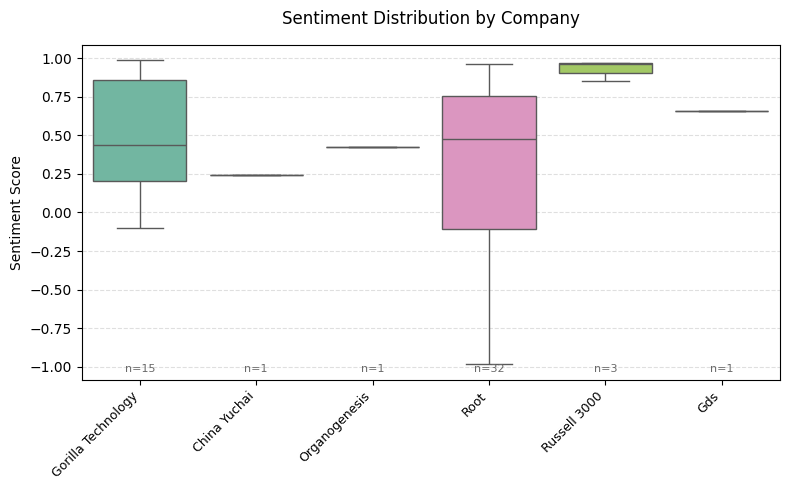

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))  # Increased width for better label spacing

# Create boxplot without redundant `hue`
sns.boxplot(
    x='company',
    y='sentiment',
    hue='company',
    data=company_context_df,
    palette='Set2'
)

# Rotate x-labels and adjust alignment
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.title('Sentiment Distribution by Company', fontsize=12, pad=15)
plt.ylabel('Sentiment Score', fontsize=10)
plt.xlabel('')  # Remove redundant x-axis label

# Add company mentions
for i, company in enumerate(company_context_df['company'].unique()):
    count = company_context_df[company_context_df['company'] == company].shape[0]
    plt.text(
        i,  # x-position aligned with box
        plt.ylim()[0] + 0.05,  # Place near bottom of plot
        f"n={count}",
        ha='center',
        fontsize=8,
        color='dimgrey'
    )

# Add horizontal grid for better readability
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Adjust ylim to accommodate annotations
plt.ylim(company_context_df['sentiment'].min() - 0.1, 
         company_context_df['sentiment'].max() + 0.1)

plt.tight_layout()  # Fix label cropping
plt.show()

**Gorilla Technology** has a generally positive sentiment, with some neutral and slightly negative mentions. The absence of significant outliers suggests that its sentiment is relatively consistent across different sources.  
**Root** shows a wider spread of sentiment scores, with more outliers in both positive and negative directions. This is likely because of the greater variation in how the company is mentioned.  
The other companies have very few data points, making it difficult to draw meaningful conclusions from the box plot. A larger dataset would be needed for a more reliable analysis.

#### Aggregated sentiment values

In [28]:
# Get average sentiments
company_sentiment_mean = company_context_df.groupby('company')['sentiment'].mean()
company_sentiment_mean.sort_values(ascending=False, inplace=True)
company_sentiment_mean

company
Russell 3000          0.928100
Gds                   0.659700
Gorilla Technology    0.457147
Organogenesis         0.421500
China Yuchai          0.246200
Root                  0.217647
Name: sentiment, dtype: float64

Based on this analysis, **Russell 3000** has the highest sentiment score, but this result may be less reliable since it is derived from only two context entries.  
On the other hand, **Root and China Yuchai** have the lowest sentiment scores, suggesting a more negative or neutral perception in the collected data. However, further validation is needed to assess whether this is due to limited data points or genuinely negative sentiment in the sources.

In [29]:
# Get average sentiments
sector_sentiment_mean = sector_context_df.groupby('sector')['sentiment'].mean()
sector_sentiment_mean.sort_values(ascending=False, inplace=True)
sector_sentiment_mean

sector
Health Technology      0.613400
Technology Services    0.553800
Finance                0.490125
Name: sentiment, dtype: float64

On average, **Health Technology and Technology Services** appear in a more positive context based on sentiment scores. While **Finance** has a slighly lower score, but it still remains in the positive range (with 0 being neutral and -1 being the most negative).  
Additionally, **Producer Manufacturing** is missing from the results because the web spider did not collect any relevant context for this sector. This may indicate either a lack of coverage in the scraped sources or a need for improved link exploration in the web scraping process.

In [30]:
weighted_sentiment = analyzer.get_weighted_sentiment(company_sentiment_mean, sector_sentiment_mean)
weighted_sentiment

,company,sector,sentiment
0,Russell 3000,NaN,0.928100
1,Gds,NaN,0.659700
2,Gorilla Technology,Technology Services,0.476477
3,Organogenesis,Health Technology,0.459880
5,Root,Finance,0.272143
4,China Yuchai,Producer Manufacturing,0.246200


As the sectors are generally positive in the contexts, the weighted average moved the sentiment values slightly up.

### Visualize the mean sentiment scores!

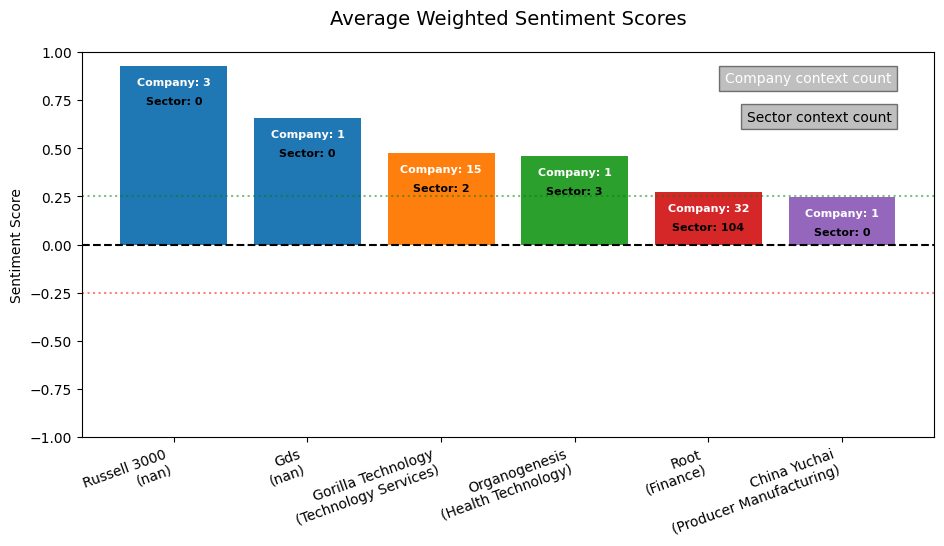

In [31]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Add colors based on sector
sectors = weighted_sentiment['sector'].unique()
colors = cm.tab10(range(len(sectors))) # colormap
sector_color_map = {sector: color for sector, color in zip(sectors, colors)}
bar_colors = [sector_color_map[row['sector']] for _, row in weighted_sentiment.iterrows()]

plt.figure(figsize=(11, 5))
plt.bar(range(len(weighted_sentiment)), weighted_sentiment['sentiment'], color=bar_colors)
plt.title('Average Weighted Sentiment Scores', fontsize=14, pad=20)
plt.ylabel('Sentiment Score', fontsize=10)

# Scores are from -1 to 1
plt.ylim(-1, 1)

# Add lines to compare
plt.axhline(0, color='black', linestyle='--')
plt.axhline(0.25, color='green', linestyle=':', alpha=0.5)
plt.axhline(-0.25, color='red', linestyle=':', alpha=0.5)

# Add sectors to x labels
labels = [f"{row['company']}\n({row['sector']})" for _, row in weighted_sentiment.iterrows()]
plt.xticks(range(len(weighted_sentiment)), labels, rotation=20, ha='right')

# Number of company context
for index, value in enumerate(weighted_sentiment['sentiment']):
    company_name = weighted_sentiment.iloc[index]['company']
    context_count = company_context_df[company_context_df['company'] == company_name].shape[0]
    plt.text(
        index,                      # x-position
        value - 0.1,               # y-position (below bar top)
        f"Company: {context_count}", 
        ha='center', color='white', fontweight='bold', fontsize=8)

# Number of sector context
for index, value in enumerate(weighted_sentiment['sentiment']):
    sector_name = weighted_sentiment.iloc[index]['sector']
    context_count = sector_context_df[sector_context_df['sector'] == sector_name].shape[0]
    plt.text(
        index,                      # x-position
        value - 0.2,               # y-position (below bar top)
        f"Sector: {context_count}", 
        ha='center', color='black', fontweight='bold', fontsize=8)

# Legend for context nums
# Company context
plt.text(
    0.95, 0.95,  # Position in top-right corner
    "Company context count",
    transform=plt.gca().transAxes,
    ha='right', va='top', color='white', fontsize=10, bbox=dict(facecolor='grey', alpha=0.5, edgecolor='black'))

plt.text(
    0.95, 0.85,  # Position in top-right corner
    "Sector context count",
    transform=plt.gca().transAxes,
    ha='right', va='top', color='black', fontsize=10, bbox=dict(facecolor='grey', alpha=0.5, edgecolor='black'))


plt.show()

Russell 3000 has the highest weighted sentiment score; however, this result should be interpreted with caution. The company was only mentioned in two contexts, and since its sector is unknown, there are no sector-level mentions contributing to the sentiment score.

### Wordcloud

#### Visualize companies

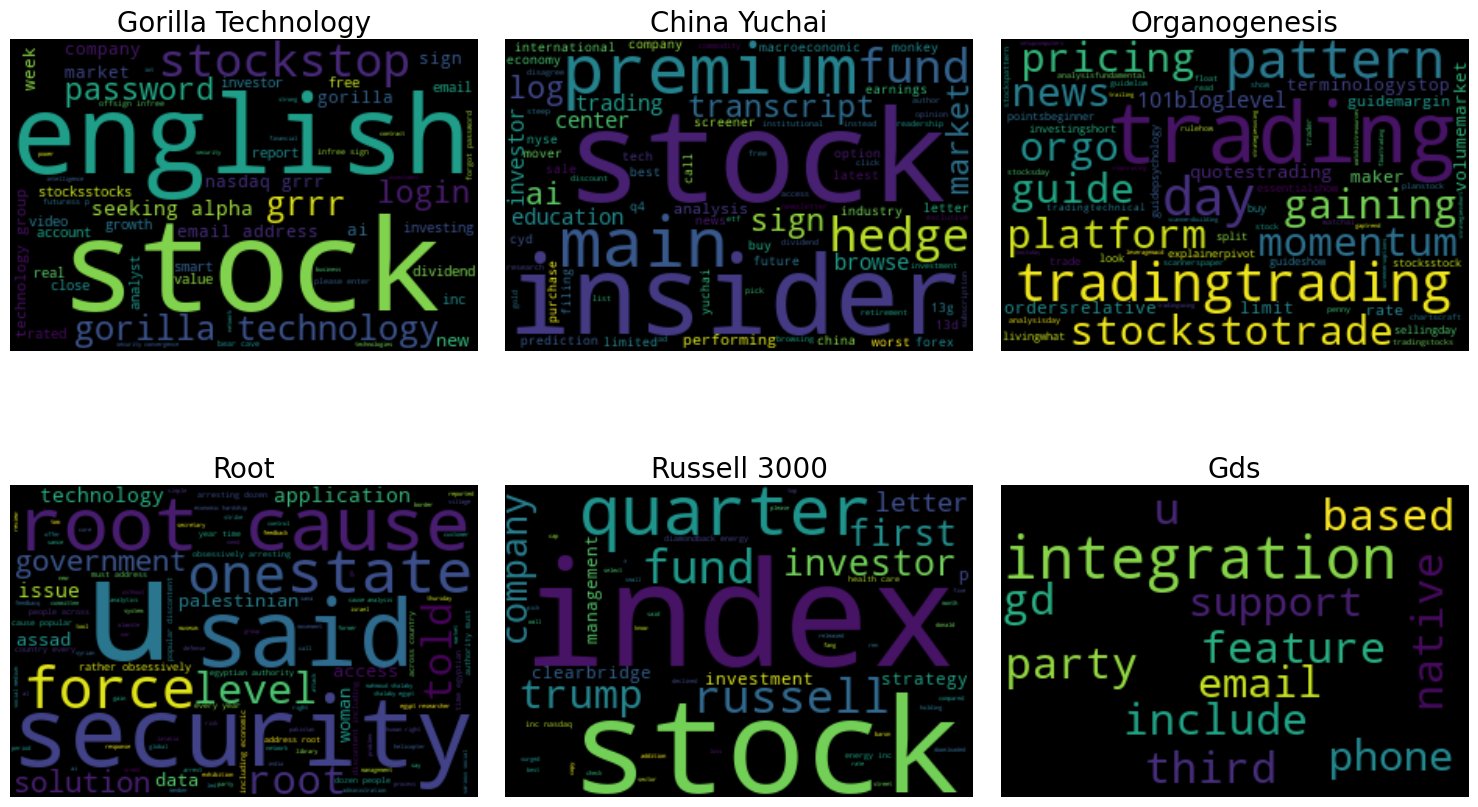

In [32]:
from wordcloud import WordCloud

companies = company_context_df['company'].unique()
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# Generate word cloud for each company
for i, company in enumerate(companies):
    company_words = analyzer.get_context_words_str(company_context_df, "company", company)
    wordcloud = WordCloud(width=300, height=200, colormap='viridis').generate(company_words)
    
    # Plot in grid
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(company, fontsize=20, pad=5)
    axes[i].axis("off")

# Adjust spacing and display
plt.tight_layout(pad=1.5, h_pad=2, w_pad=2)
plt.show()

#### Visualize Sectors

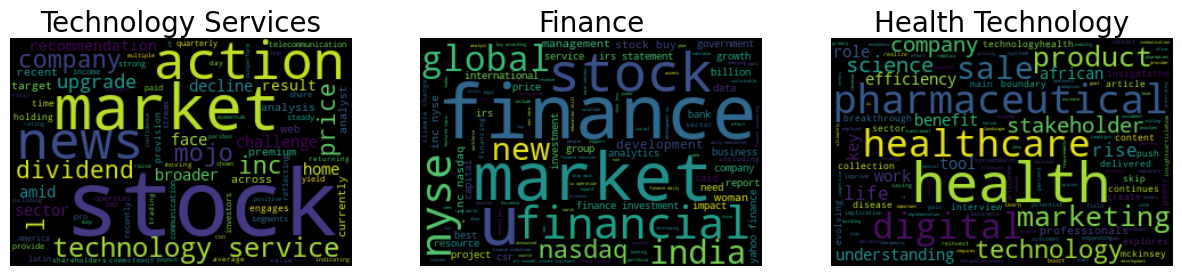

In [33]:
from wordcloud import WordCloud

sectors = sector_context_df['sector'].unique()
fig, axes = plt.subplots(1, 3, figsize=(15, 10))
axes = axes.flatten()

# Generate word cloud for each company
for i, sector in enumerate(sectors):
    sector_words = analyzer.get_context_words_str(sector_context_df, "sector", sector)
    wordcloud = WordCloud(width=300, height=200, colormap='viridis').generate(sector_words)
    
    # Plot in grid
    axes[i].imshow(wordcloud, interpolation='bilinear')
    axes[i].set_title(sector, fontsize=20, pad=5)
    axes[i].axis("off")

# Adjust spacing and display
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.show()

---

## Tool selection
### NLP 
- VADER is a great choice for analyzing short financial texts due to its rule-based approach, but it lacks deep contextual understanding
- Possible alternatives:
    - BERT (FinBERT) – A financial domain-tuned version of BERT that better understands context but requires higher computational power
    - TextBlob – A simpler alternative to VADER with basic sentiment and text processing capabilities
    - spaCy – If further text preprocessing (e.g., Named Entity Recognition) is required

### Database:
- SQLite is well-suited for small-scale projects due to its simplicity and lightweight nature. However, for scalability and multi-user access, other options could be considered
- Possible alternatives:
    - PostgreSQL – If the dataset grows, this could provide better indexing and query optimization
    - MongoDB – If handling unstructured or semi-structured data, MongoDB’s document-based storage might be more flexible than SQL

### Webspider:
- BeautifulSoup is easy to use and flexible for parsing HTML, but it’s slower than Scrapy or lxml for large-scale scraping
- Possible alternatives:
    - Scrapy – More efficient than BeautifulSoup for large-scale web scraping
    - Asyncio/Aiohttp – Can improve performance by handling multiple requests concurrently

## Difficulties with data
#### Data Quality & Relevance
- Noisy Data: Many scraped articles contained irrelevant words (e.g., login prompts, ads, or unrelated financial terms)
- Ambiguity: Some words in the context might refer to different entities (e.g., "root" in finance vs. root as a general term)

#### Limited Data Availability
- Low Mentions for Some Companies: Less popular companies (e.g., China Yuchai) had very few context mentions, making sentiment analysis less reliable
- Sector Data Gaps: Some sectors (e.g., Producer Manufacturing) were missing from the dataset due to a lack of relevant mentions

#### Web Scraping Challenges
- Inefficient Link Filtering: The spider followed many links, but only a fraction contained useful company or sector-related information
- Rate Limits & Blocking: Some sites may have imposed restrictions on scraping, requiring careful request handling

#### Sentiment Analysis Limitations
- Context Length: Shorter contexts might not provide enough sentiment clues, leading to misleading sentiment scores
- Rule-Based Approach: VADER works well for finance but lacks deep contextual understanding compared to FinBERT

## Conclusion
This project successfully implemented a data pipeline that extracts, processes, and analyzes sentiment related to various companies and sectors using web scraping, SQL databases, and sentiment analysis techniques. The final results provide insights into the sentiment distribution of different stocks and their respective industries, highlighting both strengths and limitations in the approach.

### Key findings
1. Sentiment Distribution Across Companies:
- Russell 3000 had the highest sentiment score, but this result is unreliable due to limited context availability and the absence of sector-based sentiment
- Root exhibited high variability in sentiment, with both strong positive and negative mentions, likely due to a larger number of references
- Gorilla Technology maintained a consistently positive sentiment with fewer extreme values
- Companies like China Yuchai and GDS had very few mentions, making their sentiment scores less meaningful

2. Sector-Level Sentiment Trends:
- Health Technology and Technology Services had the most positive sentiment scores, indicating a generally optimistic tone in articles mentioning these industries
- Finance had a lower but still positive sentiment, suggesting a more mixed perception, likely due to its generality
- Producer Manufacturing did not appear in the dataset, meaning no context was gathered for this sector, which could indicate a lack of relevant mentions in the articles used by the webspider

3. Data Processing and Limitations:
- The weighted sentiment calculation (70% company sentiment, 30% sector sentiment) provided a balanced approach but could be improved by adding additional data sources or adjusting the weights based on the availability of sector mentions
- The web scraping methodology worked effectively, but the BFS link-following process was time-consuming and resulted in collecting a large number of irrelevant links
- The word clouds illustrated the dominant keywords associated with each company and sector. However, some word clouds contained unrelated terms (e.g., "login" and "email"), indicating that additional text cleaning and filtering may be required

### Recommendations:
- Expand the web spider’s depth to collect 1,000+ context samples for a more robust sentiment analysis
- Integrate CW1's stock price volatility metrics to enable cross-validation between sentiment scores and market fluctuations
- Focus the analysis on larger, well-known companies (e.g., Meta, Google) to improve data availability and result reliability

### Potential project improvements
- *Improve database security*: parameterize database queries to prevent SQL injection vulnerabilities
- *Automate the data pipeline*: create a dedicated pipeline class, and schedule automatic runs
#####  Web Spider Optimizations:
- Rewrite the BFS implementation to be concurrent to optimize performance
- Implement utility-based filtering which stops exploring links if their relevance decreases over time
- Move beyond the basic queue (deque) and implement a smarter ranking system for link selection
- Apply stricter criteria to exclude irrelevant links earlier in the process

### Objectives achieved

1. **Build a webscraper** using BeautifulSoup to extract growth stocks from Investopedia’s “Best Growth Stocks” list ✅
2. **Deploy a BFS webspider** starting from 10+ financial sites (e.g., Seeking Alpha) for company and sector contexts ✅
3. **Design an SQLite database** (stockAnalysis.db) with tables for stock info, company contexts, and sector contexts, storing 200+ records ✅
4. **Clean data**, **calculate sentiment scores**, and **merge company/sector data** ✅
5. **Visualize data**: sentiment boxplots, word clouds, and weighted sector scores ✅
6. **Build Unit Tests** around the database handler, websraper and webspider classes to make sure they work as expected, and don't break with later changes ✅

## References
$^1$: https://www.investopedia.com/terms/g/growthstock.asp

---

## Testing & Validations

### Create mock tables in memory database

In [34]:
# To avoid conflict with different versions
%config SqlMagic.style = 'Default'
%reload_ext sql

In [35]:
%%sql sqlite:///:memory:
CREATE TABLE IF NOT EXISTS stock_info(
    ticker VARCHAR(10) NOT NULL UNIQUE,
    company TEXT,
    sector VARCHAR(100),
    investopedia_link TEXT,
    PRIMARY KEY (ticker)
);

Done.


[]

In [36]:
%%sql sqlite:///:memory:
CREATE TABLE IF NOT EXISTS company_context(
    company TEXT,
    context TEXT,  
    link TEXT
);

Done.


[]

In [37]:
%%sql sqlite:///:memory:
CREATE TABLE  IF NOT EXISTS sector_context(
    sector VARCHAR(100),
    context TEXT,  
    link TEXT
);

Done.


[]

### Test Database class

In [38]:
%sql sqlite:///:memory:

import unittest
from io import StringIO
from unittest.mock import patch
import sqlite3 as sql

class TestDatabase(unittest.TestCase):

    def setUp(self):
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

        # Create mock DB
        self.db = StockAnalysisDB(mock_db=True)

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()

    # Define test type when we expect no exception
    def assertNotRaises(self, exception, func, *args, **kwargs):
        try:
            func(*args, **kwargs)
        except exception as e:
            self.fail(f"Expected no {exception}, but got: {e}")

    def test_db_class_exists(self):
        self.assertIsNotNone(StockAnalysisDB)

    
     ## call_query function ##

    def test_call_query_exists(self):
        self.assertIsNotNone(StockAnalysisDB.call_query)
        
    @patch("__main__.get_ipython")
    def test_call_query_handles_exeptions(self, mock_ipython):

        # Mock an OperationalError
        mock_ipython.return_value.run_line_magic.side_effect = sql.OperationalError("sqlite3.OperationalError: syntax error")
        with self.assertRaises(sql.OperationalError) as context:
            self.db.call_query("INVALID SQL")
        self.assertIn("sqlite3.OperationalError", str(context.exception))

        # Mock an IntegrityError
        mock_ipython.return_value.run_line_magic.side_effect = sql.IntegrityError("sqlite3.IntegrityError: unique constraint failed")
        with self.assertRaises(sql.IntegrityError) as context:
            self.db.call_query("INSERT INTO stock_info VALUES ('XXX')")
        self.assertIn("sqlite3.IntegrityError", str(context.exception))
            
    
    ## validate_dict_raise (insert_into validator) function ##

    def test_validate_dict_raise_exists(self):
        self.assertIsNotNone(StockAnalysisDB.validate_dict_raise)

    def test_validate_dict_raise_exception_empty_1(self):
        test_data = None
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_empty_2(self):
        test_data = ""
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_empty_3(self):
        test_data = []
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_empty_4(self):
        test_data = {}
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_data)

    def test_validate_dict_raise_exception_not_list(self):
        test_dict = {'col1': 'link',
                        'col2': 'XXX',
                        'col3': 'text',
                        'col4': 'text'}
        with self.assertRaises(TypeError):
             StockAnalysisDB.validate_dict_raise(test_dict)

    def test_validate_dict_raise_exception_not_dict_in_list(self):
        test_list = ['text1', 'text2', 'text3', 'text4']
        with self.assertRaises(TypeError):
            StockAnalysisDB.validate_dict_raise(test_list)

    def test_validate_dict_not_raise_exception(self):
        my_test_list_dict = [{'col1': 'text', 'col2': 'XXX', 'col3': 'text', 'col4': 'text'},
                        {'col1': 'text', 'col2': 'RUA','col3': 'text', 'col4': 'text'}]
        self.assertNotRaises(TypeError, self.db.validate_dict_raise, my_test_list_dict) 

    
    ## insert_into function ##
    
    def test_insert_into_exists(self):
        self.assertIsNotNone(StockAnalysisDB.insert_into)

    def test_insert_into_wrong_table(self):
        my_test_list_dict = [{'col1': 'text', 'col2': 'XXX', 'col3': 'text', 'col4': 'text'},
                        {'col1': 'text', 'col2': 'RUA','col3': 'text', 'col4': 'text'}]
        with self.assertRaisesRegex(sql.OperationalError, r"syntax error"):
            self.db.insert_into("table", my_test_list_dict)

    def test_insert_into_wrong_column_name(self):
        my_test_list_dict = [{'col1': 'text', 'col2': 'XXX', 'col3': 'text', 'col4': 'text'},
                        {'col1': 'text', 'col2': 'RUA','col3': 'text', 'col4': 'text'}]
        with self.assertRaisesRegex(sql.OperationalError, r"has no column named"):
            self.db.insert_into("stock_info", my_test_list_dict)

    def test_insert_into_no_primary_key(self):
        my_test_list_dict = [{'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=TEM',
                              'company': 'Tempus AI Inc.',
                              'sector': 'Health Care'},]
        with self.assertRaisesRegex(sql.IntegrityError, r"constraint failed"):
            self.db.insert_into("stock_info", my_test_list_dict)

    def test_insert_into_wrong_key_type(self):
        my_test_list_dict = [{'investopedia_link': 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=TEM',
                              'ticker': 3,
                              'company': 'Tempus AI Inc.',
                              'sector': 'Health Care'},]
        with self.assertRaisesRegex(sql.IntegrityError, r"constraint failed"):
            self.db.insert_into("stock_info", my_test_list_dict)

    def test_insert_into_correct(self):
        my_test_list_dict = [{'investopedia_link': 'link',
                              'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector'}]
        
        self.db.call_query("DELETE FROM stock_info WHERE ticker='XXX'")
        self.db.insert_into("stock_info", my_test_list_dict)
        res = self.db.call_query("SELECT investopedia_link,ticker,company,sector FROM stock_info WHERE ticker = 'XXX'")

        # Verify and delete data
        self.assertEqual(res[0][0], 'link')
        self.assertEqual(res[0][1], 'XXX')
        self.assertEqual(res[0][2], 'company')
        self.assertEqual(res[0][3], 'sector')

        self.db.call_query("DELETE FROM stock_info WHERE ticker='XXX'")

    
    ## select function ##
    
    def test_select_exists(self):
        self.assertIsNotNone(StockAnalysisDB.select)

    @patch("__main__.StockAnalysisDB.call_query")
    def test_select_query_with_no_args(self, mock_execute):
        self.db.select("table")
        
        # Check if query sting is correct
        mock_execute.assert_called_once_with("SELECT * FROM table;")

    @patch("__main__.StockAnalysisDB.call_query")
    def test_select_query_with_columns(self, mock_execute):
        self.db.select("table", ['col1', 'col2', 'col3'])
        
        # Check if query sting is correct
        mock_execute.assert_called_once_with("SELECT col1, col2, col3 FROM table;")

    def test_select_return_with_no_args(self):
        # Fill the mock db
        my_test_list_dict = [{'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'}]

        self.db.call_query("DELETE FROM stock_info")
        self.db.insert_into("stock_info", my_test_list_dict)

        # Verify and delete data
        res = self.db.select("stock_info")
        self.assertEqual(len(res), 1)
        self.assertEqual(len(res[0]), 4)
        
        self.assertEqual(res[0][0], 'XXX')
        self.assertEqual(res[0][1], 'company')
        self.assertEqual(res[0][2], 'sector')
        self.assertEqual(res[0][3], 'link')

        self.db.call_query("DELETE FROM stock_info WHERE ticker='XXX'")

    def test_select_return_with_col(self):
        # Fill the mock db
        self.db.call_query("DELETE FROM stock_info")
        my_test_list_dict = [{'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'},
                              {'ticker': 'YYY',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'}]
        self.db.insert_into("stock_info", my_test_list_dict)

        # Verify and delete data
        res = self.db.select("stock_info", ['ticker'])
        self.assertEqual(len(res), 2)
        self.assertEqual(len(res[0]), 1)
        
        self.assertEqual(res[0][0], 'XXX')
        self.assertEqual(res[1][0], 'YYY')

        self.db.call_query("DELETE FROM stock_info WHERE ticker IN ('XXX', 'YYY')")

    def test_select_return_with_cols(self):
        
        self.db.call_query("DELETE FROM stock_info")
        # Fill the mock db
        my_test_list_dict = [{'ticker': 'XXX',
                              'company': 'company',
                              'sector': 'sector',
                              'investopedia_link': 'link'},
                              {'ticker': 'YYY',
                              'company': 'company2',
                              'sector': 'sector',
                              'investopedia_link': 'link'}]
        self.db.insert_into("stock_info", my_test_list_dict)

        # Verify and delete data
        res = self.db.select("stock_info", ['ticker', 'company'])
        self.assertEqual(len(res), 2)
        self.assertEqual(len(res[0]), 2)
        
        self.assertEqual(res[0][0], 'XXX')
        self.assertEqual(res[0][1], 'company')

        self.assertEqual(res[1][0], 'YYY')
        self.assertEqual(res[1][1], 'company2')

        self.db.call_query("DELETE FROM stock_info WHERE ticker IN ('XXX', 'YYY')")

suite = unittest.TestLoader().loadTestsFromTestCase(TestDatabase)
unittest.TextTestRunner(verbosity=2).run(suite)

test_call_query_exists (__main__.TestDatabase.test_call_query_exists) ... ok
test_call_query_handles_exeptions (__main__.TestDatabase.test_call_query_handles_exeptions) ... ok
test_db_class_exists (__main__.TestDatabase.test_db_class_exists) ... ok
test_insert_into_correct (__main__.TestDatabase.test_insert_into_correct) ... ok
test_insert_into_exists (__main__.TestDatabase.test_insert_into_exists) ... ok
test_insert_into_no_primary_key (__main__.TestDatabase.test_insert_into_no_primary_key) ... ok
test_insert_into_wrong_column_name (__main__.TestDatabase.test_insert_into_wrong_column_name) ... ok
test_insert_into_wrong_key_type (__main__.TestDatabase.test_insert_into_wrong_key_type) ... ok
test_insert_into_wrong_table (__main__.TestDatabase.test_insert_into_wrong_table) ... ok
test_select_exists (__main__.TestDatabase.test_select_exists) ... ok
test_select_query_with_columns (__main__.TestDatabase.test_select_query_with_columns) ... ok
test_select_query_with_no_args (__main__.TestData

<unittest.runner.TextTestResult run=23 errors=0 failures=0>

### Test Data Handler

In [39]:
%sql sqlite:///:memory:
import inspect

class TestStockDataHandler(unittest.TestCase):

    def setUp(self):
        
        self.data_handler = StockDataHandler(db=StockAnalysisDB(mock_db=True))

        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()

    def test_StockDataHandler_exists(self):
        self.assertIsNotNone(StockDataHandler)


    ## simplify_company_names function ##

    def test_simplify_company_names_exists(self):
        self.assertIsNotNone(StockDataHandler.simplify_company_names)
    
    def test_simplify_company_names_removes_suffixes(self):
        test_data = {"A Group Inc.","B Group, Inc.", "C Holdings Inc.", "D Holdings, Inc.", "E Holdings Limited",
                     "F International Limited", "G Holdings LLC", "H International Limited", "I S.A.", "J Corp.",
                     "K Co.", "L Inc.", "M, Inc."}
        res = self.data_handler.simplify_company_names(test_data)
        self.assertSetEqual(res, {"A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M"})

    ## is_link_might_be_useful function ##

    def test_is_link_might_be_useful_exists(self):
        self.assertIsNotNone(StockDataHandler.is_link_might_be_useful)

    def test_is_link_might_be_useful_not_string(self):
        self.assertFalse(self.data_handler.is_link_might_be_useful(234))
        self.assertFalse(self.data_handler.is_link_might_be_useful([]))
        self.assertFalse(self.data_handler.is_link_might_be_useful({}))

    def test_is_link_might_be_useful_1(self):
        self.assertFalse(self.data_handler.is_link_might_be_useful("link_with_javascript_salong"))

    def test_is_link_might_be_useful_2(self):
        self.assertFalse(self.data_handler.is_link_might_be_useful("link_with_terms"))

    ## get_company_keywords ##
    ## get_sector_keywords ##
    ## get_data_as_keyword_from_db function ##

    def test_get_data_as_keyword_from_db_exists(self):
        self.assertIsNotNone(StockDataHandler.get_data_as_keyword_from_db)
        self.assertIsNotNone(StockDataHandler.get_company_keywords)
        self.assertIsNotNone(StockDataHandler.get_sector_keywords)

    def test_get_data_as_keyword_from_db_DB_empty(self):
        # Make sure it's empty
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        with self.assertRaises(ValueError):
            self.data_handler.get_data_as_keyword_from_db()

        with self.assertRaises(ValueError):
            self.data_handler.get_company_keywords()

        with self.assertRaises(ValueError):
            self.data_handler.get_sector_keywords()

    def test_get_data_as_keyword_from_db_no_args(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(dh=self.data_handler)
        spider.scrape_ticker_data_from_investopedia()
        
        ret = self.data_handler.get_company_keywords()
        self.assertEqual(ret, {'cyd', 'china yuchai', 'gds', 'grrr', 'gorilla technology', 'inod', 'innodata',
                               'orgo', 'prch', 'porch', 'root','rua','russell 3000', 'sldb', 'swtx',
                               'solid biosciences','springworks therapeutics', 'vnet', 'organogenesis'})

        ret = self.data_handler.get_sector_keywords()
        self.assertEqual(ret, {'finance', 'health technology', 'producer manufacturing', 'technology services'})

        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    
    ## get_sector_keyword_if_link_contains ##
    ## get_company_keyword_if_link_contains ##
    ## get_keyword_if_link_contains ##
            
    def test_get_keyword_if_link_contains_not_string(self):
        self.assertIsNone(self.data_handler.get_company_keyword_if_link_contains(123))
        self.assertIsNone(self.data_handler.get_company_keyword_if_link_contains([]))
        self.assertIsNone(self.data_handler.get_company_keyword_if_link_contains({}))

        self.assertIsNone(self.data_handler.get_sector_keyword_if_link_contains(123))
        self.assertIsNone(self.data_handler.get_sector_keyword_if_link_contains([]))
        self.assertIsNone(self.data_handler.get_sector_keyword_if_link_contains({}))


    def test_get_keyword_if_link_contains_ticker(self):
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(dh=self.data_handler)
        spider.scrape_ticker_data_from_investopedia()
        
        self.assertEqual(self.data_handler.get_company_keyword_if_link_contains("link-with-GRRR-ticker"), 'GRRR')
        self.assertEqual(self.data_handler.get_company_keyword_if_link_contains("GRRR-ticker"), 'GRRR')
        self.assertEqual(self.data_handler.get_company_keyword_if_link_contains("GRRR.html"), 'GRRR')
        self.assertEqual(self.data_handler.get_company_keyword_if_link_contains("something-GRRR.html"), 'GRRR')        
        
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    def test_get_keyword_if_link_contains_spaces_sector(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(dh=self.data_handler)
        spider.scrape_ticker_data_from_investopedia()
        
        self.assertEqual(self.data_handler.
                         get_sector_keyword_if_link_contains("something-Health-Technology-sector.html"), 'Health Technology')
        self.assertEqual(self.data_handler.
                         get_sector_keyword_if_link_contains("Health-Technology-sector.html"), 'Health Technology')
        self.assertEqual(self.data_handler.
                         get_sector_keyword_if_link_contains("/Health-Technology-sector/valami.html"), 'Health Technology')

        
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

    def test_get_keyword_if_link_contains_spaces_sector_2(self):
        
        # Make sure SB is empty, and fill
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")
        spider = InvestopediaWebSpider(dh=self.data_handler)
        spider.scrape_ticker_data_from_investopedia()
    
        self.assertEqual(self.data_handler.
                         get_sector_keyword_if_link_contains("something_Health_Technology_sector.html"), 'Health Technology')
        self.assertEqual(self.data_handler.
                         get_sector_keyword_if_link_contains("Health_Technology_sector_something.html"), 'Health Technology')
        self.assertEqual(self.data_handler.
                         get_sector_keyword_if_link_contains("/Health_Technology_sector/something"), 'Health Technology')
        
        self.data_handler.stock_db.call_query("DELETE FROM stock_info;")

suite = unittest.TestLoader().loadTestsFromTestCase(TestStockDataHandler)
unittest.TextTestRunner(verbosity=2).run(suite)

test_StockDataHandler_exists (__main__.TestStockDataHandler.test_StockDataHandler_exists) ... ok
test_get_data_as_keyword_from_db_DB_empty (__main__.TestStockDataHandler.test_get_data_as_keyword_from_db_DB_empty) ... ok
test_get_data_as_keyword_from_db_exists (__main__.TestStockDataHandler.test_get_data_as_keyword_from_db_exists) ... ok
test_get_data_as_keyword_from_db_no_args (__main__.TestStockDataHandler.test_get_data_as_keyword_from_db_no_args) ... ok
test_get_keyword_if_link_contains_not_string (__main__.TestStockDataHandler.test_get_keyword_if_link_contains_not_string) ... ok
test_get_keyword_if_link_contains_spaces_sector (__main__.TestStockDataHandler.test_get_keyword_if_link_contains_spaces_sector) ... ok
test_get_keyword_if_link_contains_spaces_sector_2 (__main__.TestStockDataHandler.test_get_keyword_if_link_contains_spaces_sector_2) ... ok
test_get_keyword_if_link_contains_ticker (__main__.TestStockDataHandler.test_get_keyword_if_link_contains_ticker) ... ok
test_is_link_mig

<unittest.runner.TextTestResult run=14 errors=0 failures=0>

### Test Web Spider

### Test BeautifulSoup function

In [40]:
%sql sqlite:///:memory:

class TestGetBSFromURL(unittest.TestCase):

    def setUp(self):
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()
    
    # test what happens when bs can't be created by mocking the urlopen function
    @patch("__main__.urlopen")
    def test_http_error(self, mock_urlopen):
        mock_urlopen.side_effect = HTTPError(
            url = BASE_URL,
            code = 404,
            msg = 'Not Found',
            hdrs = {},
            fp = None)

        bs = get_bs_from_url(BASE_URL)
        self.assertIsNone(bs)

    def test_valid_url(self):
        bs = get_bs_from_url(BASE_URL)
        self.assertIsNotNone(bs)
        self.assertIn("Growth Stocks", str(bs))
    
    # test what happens when the link is wrong by mocking the urlopen function
    @patch("__main__.urlopen")
    def test_wrong_url_and_no_bs(self, mock_urlopen):
        mock_urlopen.side_effect = URLError("No route to host")
        bs = get_bs_from_url("https://www.invesftopedia.com/the-best-growth-stocks-8783031")
        self.assertIsNone(bs)

suite = unittest.TestLoader().loadTestsFromTestCase(TestGetBSFromURL)
unittest.TextTestRunner(verbosity=2).run(suite)

test_http_error (__main__.TestGetBSFromURL.test_http_error) ... ok
test_valid_url (__main__.TestGetBSFromURL.test_valid_url) ... ok
test_wrong_url_and_no_bs (__main__.TestGetBSFromURL.test_wrong_url_and_no_bs) ... ok

----------------------------------------------------------------------
Ran 3 tests in 5.524s

OK


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

In [44]:
class TestWebSpider(unittest.TestCase):
    def setUp(self):
        
        self.ws = InvestopediaWebSpider(dh=StockDataHandler(StockAnalysisDB(mock_db=True)))
        # Suppress stdout automatically
        self.patcher = patch('sys.stdout', new_callable=StringIO)
        self.mock_stdout = self.patcher.start()

    def tearDown(self):
        # Restore stdout after test
        self.patcher.stop()
        pass
    
    def test_webspider_class_exists(self):
        self.assertIsNotNone(InvestopediaWebSpider)

    
    # Utility functions #
    # convert_relative_URL function ##

    def test_convert_relative_URL_exists(self):
        self.assertIsNotNone(InvestopediaWebSpider.convert_if_relative_URL)
    
    def test_convert_relative_URL_non_string(self):
        self.assertIsNone(self.ws.convert_if_relative_URL("",34))
        self.assertIsNone(self.ws.convert_if_relative_URL("",[]))
        self.assertIsNone(self.ws.convert_if_relative_URL("",{}))

    def test_convert_relative_URL_base_empty(self):
        self.assertIsNone(self.ws.convert_if_relative_URL("","#something"))
    
    def test_convert_relative_URL_base_non_string(self):
        self.assertIsNone(self.ws.convert_if_relative_URL(34,"#something"))
        self.assertIsNone(self.ws.convert_if_relative_URL([],"#something"))
        self.assertIsNone(self.ws.convert_if_relative_URL({},"#something"))

    def test_convert_relative_URL_non_relative(self):
        self.assertEqual("http://something.com", self.ws.convert_if_relative_URL("","http://something.com"))
        self.assertEqual("https://something.com", self.ws.convert_if_relative_URL("","https://something.com"))
        self.assertEqual("https://something.com/path/to/smg", self.ws.convert_if_relative_URL("","https://something.com/path/to/smg"))
        self.assertEqual("http://something.com/search?q=query", self.ws.convert_if_relative_URL("","http://something.com/search?q=query"))
        self.assertEqual("http://something.com/page#section1", self.ws.convert_if_relative_URL("","http://something.com/page#section1"))
        self.assertEqual("http://something.com/path?q=query#section1", self.ws.convert_if_relative_URL("","http://something.com/path?q=query#section1"))

    def test_convert_relative_URL_converted_1(self):
        self.assertEqual("http://something.com/path/to/something", self.ws.convert_if_relative_URL("http://something.com","/path/to/something"))

    def test_convert_relative_URL_converted_2(self):
        self.assertEqual("http://something.com/to/something", self.ws.convert_if_relative_URL("http://something.com/path","/to/something"))
    
    def test_convert_relative_URL_converted_3(self):
        self.assertEqual("http://something.com/something", self.ws.convert_if_relative_URL("http://something.com","./something"))
 
    def test_convert_relative_URL_converted_4(self):
        self.assertEqual("http://something.com/path/something", self.ws.convert_if_relative_URL("http://something.com/path","./something"))

    def test_convert_relative_URL_converted_5(self):
        self.assertEqual("http://something.com/path/something", self.ws.convert_if_relative_URL("http://something.com/path/to","../something"))

    def test_convert_relative_URL_converted_6(self):
        self.assertEqual("http://something.com/path/to/something", self.ws.convert_if_relative_URL("http://something.com/path/to","something"))

    def test_convert_relative_URL_converted_7(self):
        self.assertEqual("http://something.com/search?q=query", self.ws.convert_if_relative_URL("http://something.com","/search?q=query"))

    def test_convert_relative_URL_converted_8(self):
        self.assertEqual("http://something.com/page#section", self.ws.convert_if_relative_URL("http://something.com/page","#section"))

    def test_convert_relative_URL_converted_9(self):
        self.assertEqual("http://something.com/path?q=query#section", self.ws.convert_if_relative_URL("http://something.com","/path?q=query#section"))

    # inherits schema
    def test_convert_relative_URL_converted_10(self):
        self.assertEqual("http://example.com/path", self.ws.convert_if_relative_URL("http://something.com", "//example.com/path"))
        self.assertEqual("https://example.com/path", self.ws.convert_if_relative_URL("https://something.com", "//example.com/path"))
        
    def test_convert_relative_URL_empty(self):
        self.assertEqual("http://something.com/path", self.ws.convert_if_relative_URL("http://something.com/path", ""))


    ## normalize_url function ##

    def test_normalize_url_exists(self):
        self.assertIsNotNone(InvestopediaWebSpider.normalize_url)

    def test_normalize_url_no_query(self):
        self.assertEqual("http://example.com/path", self.ws.normalize_url("", "http://example.com/path"))
        self.assertEqual("https://example.com", self.ws.normalize_url("", "https://example.com"))
        self.assertEqual("https://example.com/", self.ws.normalize_url("", "https://example.com/"))
    
    def test_normalize_url_with_query_and_fragment(self):
        self.assertEqual("https://example.com/path/to/page", 
                         self.ws.normalize_url("", "https://example.com/path/to/page?query=123#section"))
    
    def test_normalize_url_with_complex_path(self):
        self.assertEqual("https://www.example.com/path/to/page.html",
                         self.ws.normalize_url("", "https://www.example.com/path/to/page.html?foo=bar&baz=qux#anchor"))

    def test_normalize_url_relative(self):
        self.assertEqual("https://www.example.com/path/to/page.html",
                         self.ws.normalize_url("https://www.example.com", "/path/to/page.html?foo=bar&baz=qux#anchor"))

    
    ## scrape_ticker_data_from_investopedia function ##
    
    def test_scrape_ticker_data_from_investopediaÜexists(self):
        self.assertIsNotNone(InvestopediaWebSpider.scrape_ticker_data_from_investopedia)

    def test_scrape_ticker_data_from_investopedia_data_fills_DB(self):
        test_spider = InvestopediaWebSpider(dh=self.ws.data_handler)
        test_spider.scrape_ticker_data_from_investopedia()

        # DB should be filled with expected results
        res = %sql "SELECT * FROM stock_info"
        expected_list = [('GRRR','Gorilla Technology Group Inc.', 'Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=GRRR'),
        ('ORGO','Organogenesis Holdings Inc.', 'Health Technology','https://www.investopedia.com/markets/quote?tvwidgetsymbol=ORGO'),
        ('CYD','China Yuchai International Limited','Producer Manufacturing','https://www.investopedia.com/markets/quote?tvwidgetsymbol=CYD'),
        ('SLDB','Solid Biosciences Inc.','Health Technology', 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=SLDB'),
        ('GDS', 'GDS Holdings Limited', 'Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=GDS'),
        ('PRCH','Porch Group, Inc.','Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=PRCH'),
        ('ROOT','Root, Inc.','Finance','https://www.investopedia.com/markets/quote?tvwidgetsymbol=ROOT'),
        ('SWTX','SpringWorks Therapeutics, Inc.','Health Technology','https://www.investopedia.com/markets/quote?tvwidgetsymbol=SWTX'),
        ('VNET','VNET Group, Inc.','Technology Services', 'https://www.investopedia.com/markets/quote?tvwidgetsymbol=VNET'),
        ('INOD','Innodata Inc.','Technology Services','https://www.investopedia.com/markets/quote?tvwidgetsymbol=INOD'),
        ('RUA',	'Russell 3000',	None,'https://www.investopedia.com/markets/quote?tvwidgetsymbol=RUA')]

        %sql "DELETE FROM stock_info;"

        self.assertListEqual(res, expected_list)

    ## insert_company_context function ##
    ## insert_sector_context function ##

    def test_insert_company_context(self):

        self.ws.company_link_context_map["company1"] = {"https://example.com": {"context1", "context2"}}
        
        # Execute
        self.ws.insert_company_context()
        
        # Verify company context
        company_res = self.ws.data_handler.stock_db.select("company_context")
        self.assertEqual(company_res[0][0], "company1")
        self.assertEqual(company_res[0][2], "https://example.com")
       
    def test_insert_sector_context(self):

        self.ws.sector_link_context_map["sector1"] = {"https://example.com": {"context1"}}
        
        # Execute
        self.ws.insert_sector_context()
        
        # Verify sector context
        sector_res = self.ws.data_handler.stock_db.select("sector_context")
        self.assertEqual(sector_res[0][0], "sector1")
        self.assertEqual(sector_res[0][1], "context1")
        self.assertEqual(sector_res[0][2], "https://example.com")
    
suite = unittest.TestLoader().loadTestsFromTestCase(TestWebSpider)
unittest.TextTestRunner(verbosity=2).run(suite)

test_convert_relative_URL_base_empty (__main__.TestWebSpider.test_convert_relative_URL_base_empty) ... ok
test_convert_relative_URL_base_non_string (__main__.TestWebSpider.test_convert_relative_URL_base_non_string) ... ok
test_convert_relative_URL_converted_1 (__main__.TestWebSpider.test_convert_relative_URL_converted_1) ... ok
test_convert_relative_URL_converted_10 (__main__.TestWebSpider.test_convert_relative_URL_converted_10) ... ok
test_convert_relative_URL_converted_2 (__main__.TestWebSpider.test_convert_relative_URL_converted_2) ... ok
test_convert_relative_URL_converted_3 (__main__.TestWebSpider.test_convert_relative_URL_converted_3) ... ok
test_convert_relative_URL_converted_4 (__main__.TestWebSpider.test_convert_relative_URL_converted_4) ... ok
test_convert_relative_URL_converted_5 (__main__.TestWebSpider.test_convert_relative_URL_converted_5) ... ok
test_convert_relative_URL_converted_6 (__main__.TestWebSpider.test_convert_relative_URL_converted_6) ... ok
test_convert_relativ

<unittest.runner.TextTestResult run=26 errors=0 failures=0>

---

In [42]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
